[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic03_production_figures.ipynb)

# Topic 3: Production Optimization -- Figure Generator

Regenerates every static figure used in
[`slides/03_production-optimization/deck.qmd`](../slides/03_production-optimization/deck.qmd)
from its underlying formulas, replacing the legacy PowerPoint slide crops
that the Marp version of this deck inherited.

Same conventions as the Topic 2 figure notebook: navy/amber palette, serif
type, saved at 150 dpi into `../slides/03_production-optimization/figs/`.

The cost figures follow the running example in Nicholson & Snyder (11th ed.,
Examples 10.1, 10.5, 11.3 and 11.4): Cobb-Douglas $q = K^{1/2} L^{1/2}$ with
wage $w = 12$ and rental rate of capital $v = 3$. Then $L^c = q/2$,
$K^c = 2q$, long-run cost is $C = 12q$, and with capital fixed at $K_1$ the
short-run cost is $SC = 3K_1 + 12q^2/K_1$. The profit-maximization figures
use the sub shop of NS Example 11.1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"
GREY = "#8a8a8a"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
})

FIGDIR = Path("../slides/03_production-optimization/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

## Technology: from discrete techniques to a smooth isoquant

saved ..\slides\03_production-optimization\figs\discrete-to-smooth-isoquant.png


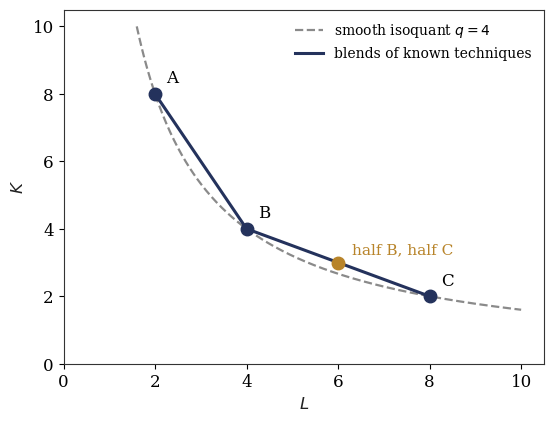

In [2]:
# Three known recipes for the same output, plus the blends between them.
tech = {"A": (2.0, 8.0), "B": (4.0, 4.0), "C": (8.0, 2.0)}   # (L, K)

fig, ax = plt.subplots(figsize=(6.2, 4.6))
L = np.linspace(1.6, 10, 300)
ax.plot(L, 16 / L, color=GREY, lw=1.6, ls="--", label="smooth isoquant $q=4$")
pts = np.array([tech[k] for k in "ABC"])
ax.plot(pts[:, 0], pts[:, 1], "-", color=NAVY, lw=2.2,
        label="blends of known techniques")
ax.plot(pts[:, 0], pts[:, 1], "o", color=NAVY, ms=9, zorder=5)
for k, (l, kk) in tech.items():
    ax.annotate(k, (l, kk), textcoords="offset points", xytext=(8, 8), fontsize=12)
mid = (tech["B"][0] + tech["C"][0]) / 2, (tech["B"][1] + tech["C"][1]) / 2
ax.plot(*mid, "o", color=AMBER, ms=9, zorder=6)
ax.annotate("half B, half C", mid, textcoords="offset points", xytext=(10, 6),
            fontsize=11, color=AMBER)
ax.set_xlim(0, 10.5); ax.set_ylim(0, 10.5)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "discrete-to-smooth-isoquant.png")
plt.show()

saved ..\slides\03_production-optimization\figs\isoquant-map.png


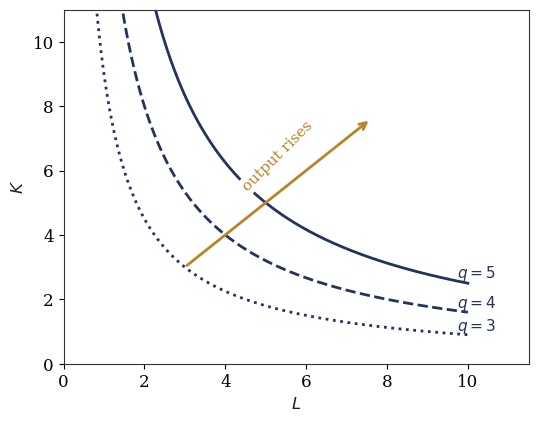

In [3]:
# Isoquant map: higher output to the northeast.
fig, ax = plt.subplots(figsize=(6.0, 4.6))
L = np.linspace(0.6, 10, 400)
for q, style in [(3, ":"), (4, "--"), (5, "-")]:
    ax.plot(L, q**2 / L, color=NAVY, lw=2.0, ls=style)
    ax.annotate(f"$q={q}$", (9.6, q**2 / 9.6), fontsize=11, color=NAVY,
                textcoords="offset points", xytext=(4, 2))
ax.annotate("", xy=(7.6, 7.6), xytext=(3.0, 3.0),
            arrowprops=dict(arrowstyle="->", color=AMBER, lw=2))
ax.annotate("output rises", (5.3, 5.3), color=AMBER, fontsize=11, rotation=45,
            ha="center", va="bottom",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.set_xlim(0, 11.5); ax.set_ylim(0, 11)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
savefig(fig, "isoquant-map.png")
plt.show()

saved ..\slides\03_production-optimization\figs\mrts-diminishing.png


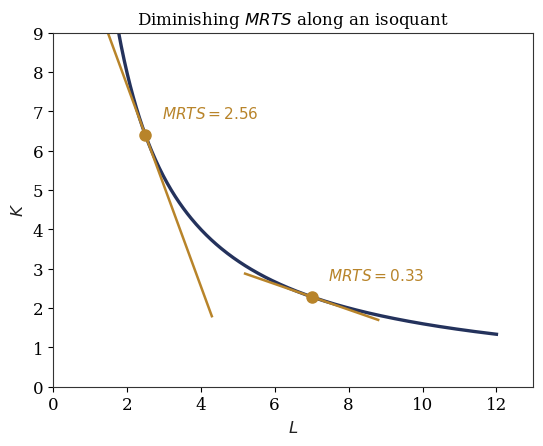

In [4]:
# Diminishing MRTS: tangent lines flatten as L rises along one isoquant.
q = 4.0
L = np.linspace(1.2, 12, 400)
K = q**2 / L

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot(L, K, color=NAVY, lw=2.4)
for L0, colr in [(2.5, AMBER), (7.0, AMBER)]:
    K0 = q**2 / L0
    slope = -q**2 / L0**2                      # dK/dL along the isoquant
    seg = np.linspace(L0 - 1.8, L0 + 1.8, 2)
    ax.plot(seg, K0 + slope * (seg - L0), color=colr, lw=1.8)
    ax.plot(L0, K0, "o", color=colr, ms=8, zorder=5)
    ax.annotate(f"$MRTS = {-slope:.2f}$", (L0, K0), textcoords="offset points",
                xytext=(12, 12), fontsize=11, color=colr)
ax.set_xlim(0, 13); ax.set_ylim(0, 9)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.set_title("Diminishing $MRTS$ along an isoquant", fontsize=12)
savefig(fig, "mrts-diminishing.png")
plt.show()

saved ..\slides\03_production-optimization\figs\elasticity-of-substitution.png


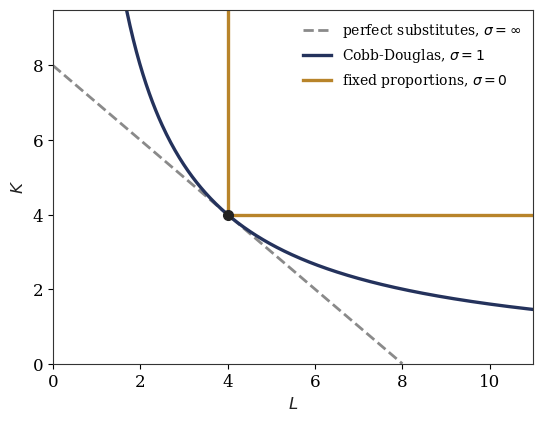

In [5]:
# Elasticity of substitution: three isoquants through the same point.
# Perfect substitutes (sigma = infinity), Cobb-Douglas (sigma = 1) and
# fixed proportions (sigma = 0). NS Figure 9.4.
fig, ax = plt.subplots(figsize=(6.2, 4.6))
L = np.linspace(1.2, 11, 400)
ax.plot([0, 8], [8, 0], color=GREY, lw=2.0, ls="--",
        label=r"perfect substitutes, $\sigma = \infty$")
ax.plot(L, 16 / L, color=NAVY, lw=2.4, label=r"Cobb-Douglas, $\sigma = 1$")
ax.plot([4, 4, 11], [9.5, 4, 4], color=AMBER, lw=2.4,
        label=r"fixed proportions, $\sigma = 0$")
ax.plot(4, 4, "o", color="#222222", ms=7, zorder=6)
ax.set_xlim(0, 11); ax.set_ylim(0, 9.5)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "elasticity-of-substitution.png")
plt.show()

saved ..\slides\03_production-optimization\figs\technical-progress.png


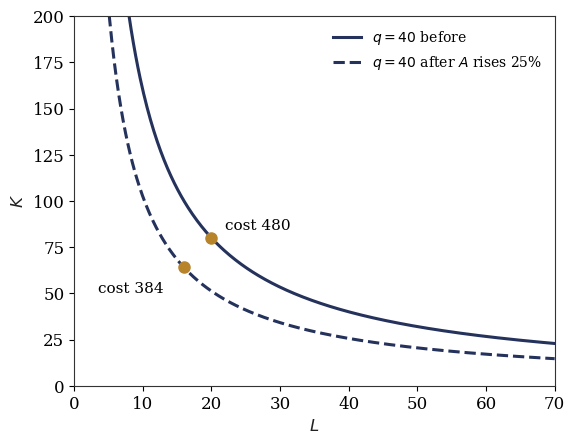

In [6]:
# Technical progress: q = A sqrt(K L). When A rises from 1 to 1.25 the
# isoquant for q = 40 moves toward the origin. At w = 12, v = 3 the
# cost-minimizing bundle moves from (20, 80) to (16, 64) and cost falls
# from 480 to 384. NS Figure 9.5.
w, v, q = 12.0, 3.0, 40.0
fig, ax = plt.subplots(figsize=(6.2, 4.8))
L = np.linspace(4, 70, 400)
for A, style, lab, off in [(1.0, "-", "$q = 40$ before", (10, 6)),
                           (1.25, "--", "$q = 40$ after $A$ rises 25%", (-62, -18))]:
    ax.plot(L, (q / A) ** 2 / L, color=NAVY, lw=2.2, ls=style, label=lab)
    Ls = (q / A) * np.sqrt(v / w); Ks = (w / v) * Ls
    ax.plot(Ls, Ks, "o", color=AMBER, ms=8, zorder=6)
    ax.annotate(f"cost {w * Ls + v * Ks:.0f}", (Ls, Ks),
                textcoords="offset points", xytext=off, fontsize=11)
ax.set_xlim(0, 70); ax.set_ylim(0, 200)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "technical-progress.png")
plt.show()

## Cost minimization: isocost lines, the tangency, the expansion path

saved ..\slides\03_production-optimization\figs\isocost-family.png


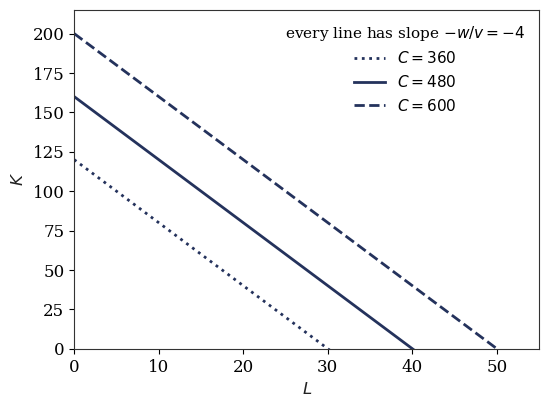

In [7]:
# A family of parallel isocost lines, slope -w/v.
w, v = 12.0, 3.0
fig, ax = plt.subplots(figsize=(6.0, 4.4))
L = np.linspace(0, 55, 200)
for C, style in [(360, ":"), (480, "-"), (600, "--")]:
    ax.plot(L, C / v - (w / v) * L, color=NAVY, lw=2.0, ls=style,
            label=f"$C={C:g}$")
ax.legend(frameon=False, fontsize=11, loc="upper right",
          title="every line has slope $-w/v=-4$", title_fontsize=11)
ax.set_xlim(0, 55); ax.set_ylim(0, 215)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
savefig(fig, "isocost-family.png")
plt.show()

saved ..\slides\03_production-optimization\figs\cost-min-tangency.png


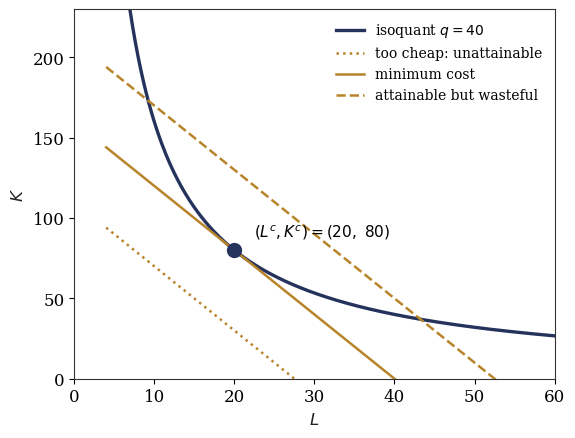

L=20.000  K=80.000  C=480.000


In [8]:
# The cost-minimizing input choice for a given output (NS Example 10.1).
w, v, q = 12.0, 3.0, 40.0
# tangency: MRTS = K/L = w/v  ->  K = (w/v) L ; and K*L = q^2
Lc = q * np.sqrt(v / w)
Kc = (w / v) * Lc
Cmin = w * Lc + v * Kc

fig, ax = plt.subplots(figsize=(6.2, 4.8))
L = np.linspace(4, 70, 400)
ax.plot(L, q**2 / L, color=NAVY, lw=2.4, label=f"isoquant $q={q:g}$")
for C, style, lab in [(Cmin - 150, ":", "too cheap: unattainable"),
                      (Cmin, "-", "minimum cost"),
                      (Cmin + 150, "--", "attainable but wasteful")]:
    ax.plot(L, C / v - (w / v) * L, color=AMBER, lw=1.8, ls=style, label=lab)
ax.plot(Lc, Kc, "o", color=NAVY, ms=10, zorder=6)
ax.annotate(rf"$(L^c,K^c)=({Lc:g},\ {Kc:g})$", (Lc, Kc),
            textcoords="offset points", xytext=(14, 10), fontsize=11)
ax.set_xlim(0, 60); ax.set_ylim(0, 230)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "cost-min-tangency.png")
plt.show()
print(f"L={Lc:.3f}  K={Kc:.3f}  C={Cmin:.3f}")

saved ..\slides\03_production-optimization\figs\expansion-path.png


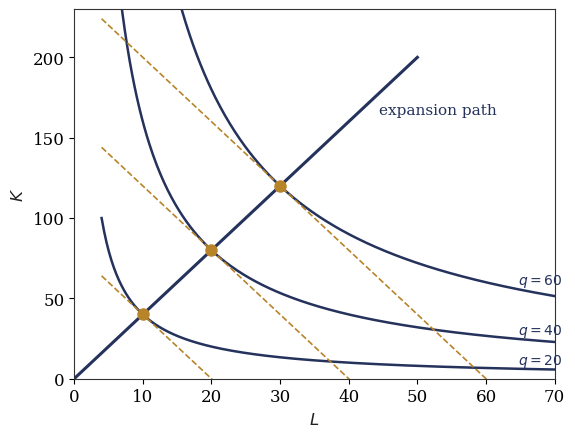

In [9]:
# Expansion path: tangencies for a sequence of output levels.
w, v = 12.0, 3.0
fig, ax = plt.subplots(figsize=(6.2, 4.8))
L = np.linspace(4, 75, 400)
for q in (20, 40, 60):
    ax.plot(L, q**2 / L, color=NAVY, lw=1.8)
    Ls = q * np.sqrt(v / w); Ks = (w / v) * Ls
    C = w * Ls + v * Ks
    ax.plot(L, C / v - (w / v) * L, color=AMBER, lw=1.2, ls="--")
    ax.plot(Ls, Ks, "o", color=AMBER, ms=8, zorder=6)
    ax.annotate(f"$q={q}$", (64, q**2 / 64), fontsize=10, color=NAVY,
                textcoords="offset points", xytext=(3, 3))
Lp = np.linspace(0, 50, 10)
ax.plot(Lp, (w / v) * Lp, color=NAVY, lw=2.2, ls="-")
ax.annotate("expansion path", (42, (w / v) * 42), color=NAVY, fontsize=11,
            textcoords="offset points", xytext=(12, -4))
ax.set_xlim(0, 70); ax.set_ylim(0, 230)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
savefig(fig, "expansion-path.png")
plt.show()

## Returns to scale and the shape of cost

For Cobb-Douglas $F=K^\alpha L^\beta$ the cost function is proportional to
$q^{1/(\alpha+\beta)}$: linear under constant returns, convex under
decreasing returns, concave under increasing returns.

saved ..\slides\03_production-optimization\figs\returns-to-scale-costs.png


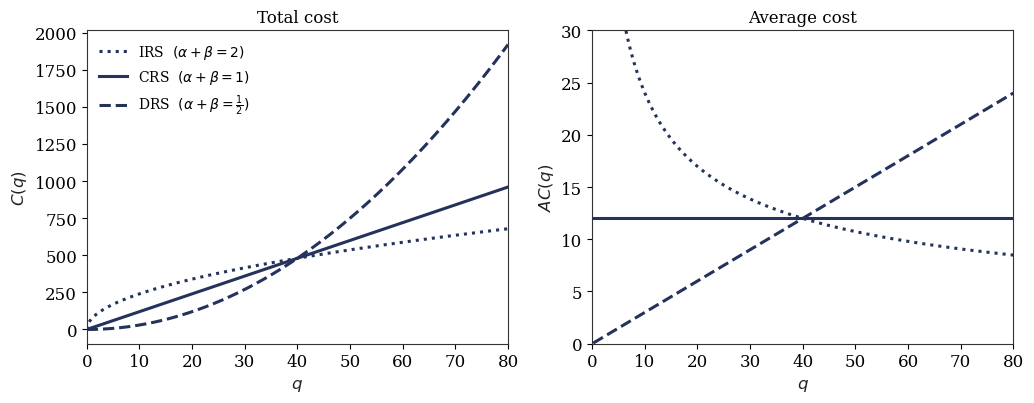

In [10]:
q = np.linspace(0, 80, 400)
cases = [("IRS  $(\\alpha+\\beta=2)$", 0.5, ":"),
         ("CRS  $(\\alpha+\\beta=1)$", 1.0, "-"),
         ("DRS  $(\\alpha+\\beta=\\frac{1}{2})$", 2.0, "--")]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for lab, power, style in cases:
    C = 480 * (q / 40) ** power     # CRS case is C = 12q; all three meet at q=40
    axes[0].plot(q, C, color=NAVY, lw=2.2, ls=style, label=lab)
    with np.errstate(divide="ignore", invalid="ignore"):
        AC = np.where(q > 0, C / q, np.nan)
    axes[1].plot(q, AC, color=NAVY, lw=2.2, ls=style, label=lab)
axes[0].set_xlabel("$q$"); axes[0].set_ylabel("$C(q)$")
axes[0].set_title("Total cost", fontsize=12)
axes[0].legend(frameon=False, fontsize=10, loc="upper left")
axes[1].set_xlabel("$q$"); axes[1].set_ylabel("$AC(q)$")
axes[1].set_title("Average cost", fontsize=12)
axes[1].set_ylim(0, 30)
for ax in axes:
    ax.set_xlim(0, 80)
fig.tight_layout()
savefig(fig, "returns-to-scale-costs.png")
plt.show()

saved ..\slides\03_production-optimization\figs\sac-smc-short-run.png


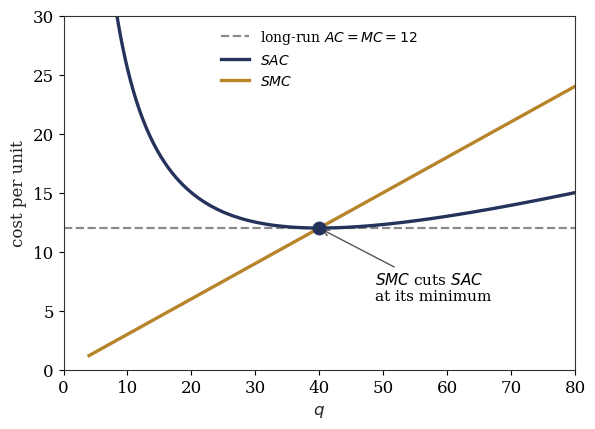

SAC minimised at q = 40.00


In [11]:
# Short-run average and marginal cost with capital fixed at K1 = 80
# (NS Example 10.5, Table 10.2):  SC = 240 + 3 q^2 / 20.
w, v, K1 = 12.0, 3.0, 80.0
q = np.linspace(4, 80, 400)
SAC = v * K1 / q + w * q / K1
SMC = 2 * w * q / K1
qmin = np.sqrt(v / w) * K1                     # = 40

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.axhline(12, color=GREY, lw=1.6, ls="--", label="long-run $AC = MC = 12$")
ax.plot(q, SAC, color=NAVY, lw=2.4, label="$SAC$")
ax.plot(q, SMC, color=AMBER, lw=2.4, label="$SMC$")
ax.plot(qmin, 12, "o", color=NAVY, ms=9, zorder=5)
ax.annotate("$SMC$ cuts $SAC$\nat its minimum", (qmin, 12),
            textcoords="offset points", xytext=(40, -52), fontsize=11,
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1))
ax.set_xlim(0, 80); ax.set_ylim(0, 30)
ax.set_xlabel("$q$"); ax.set_ylabel("cost per unit")
ax.legend(frameon=False, fontsize=10, loc="upper center")
savefig(fig, "sac-smc-short-run.png")
plt.show()
print(f"SAC minimised at q = {qmin:.2f}")

saved ..\slides\03_production-optimization\figs\short-run-long-run-envelope.png


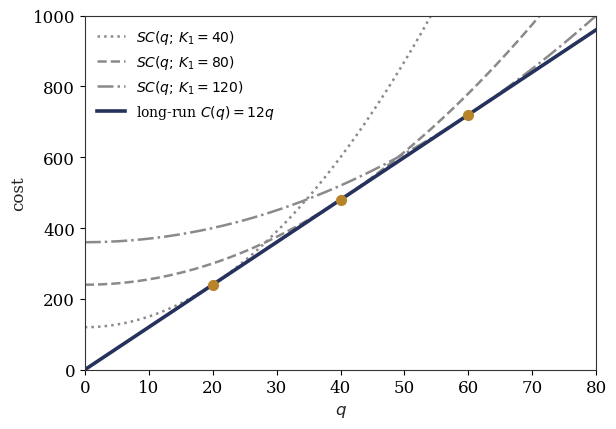

In [12]:
# Short-run cost curves and their lower envelope, the long-run curve.
# q = sqrt(K L), w = 12, v = 3:  SC(q; K1) = 3 K1 + 12 q^2 / K1 ;  C(q) = 12 q.
w, v = 12.0, 3.0
q = np.linspace(0, 80, 400)
fig, ax = plt.subplots(figsize=(6.6, 4.6))
for K1, style in [(40, ":"), (80, "--"), (120, "-.")]:
    ax.plot(q, v * K1 + w * q**2 / K1, color=GREY, lw=1.8, ls=style,
            label=f"$SC(q;\\,K_1={K1})$")
    qt = K1 / 2                              # SC touches C(q) where K1 = 2q
    ax.plot(qt, 12 * qt, "o", color=AMBER, ms=7, zorder=5)
ax.plot(q, 12 * q, color=NAVY, lw=2.6, label="long-run $C(q) = 12q$")
ax.set_xlim(0, 80); ax.set_ylim(0, 1000)
ax.set_xlabel("$q$"); ax.set_ylabel("cost")
ax.legend(frameon=False, fontsize=10, loc="upper left")
savefig(fig, "short-run-long-run-envelope.png")
plt.show()

## Profit maximization

Two cases. The price-taking firm is the running example in the short run
($K_1 = 80$): it supplies where $p = SMC = 3q/10$ and breaks even at
$p = 12$ (NS Examples 11.3-11.4). The firm with market power is the sub shop
of NS Example 11.1: demand $q = 100 - 10p$, so $p(q) = 10 - q/10$, with a
constant marginal cost of 4. Then $q^* = 30$, $p^* = 7$, profit 90.

saved ..\slides\03_production-optimization\figs\profit-max-panel.png


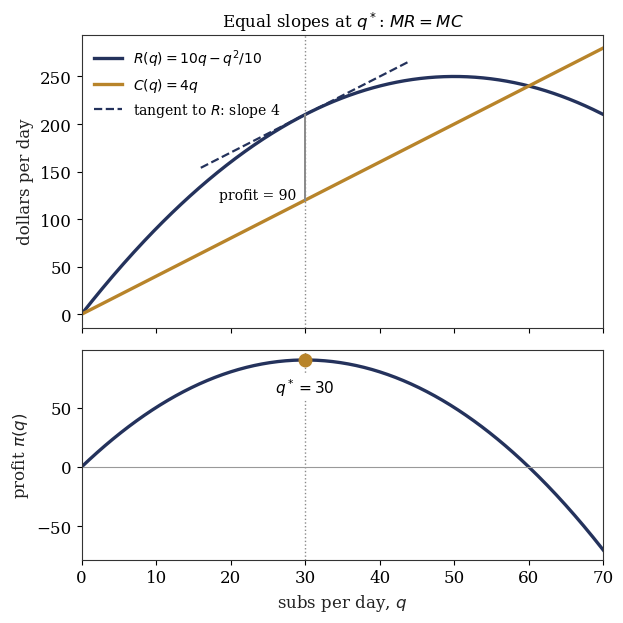

In [13]:
# Sub shop: revenue, cost and profit. Parallel tangents at q* = 30.
q = np.linspace(0, 70, 400)
R = 10 * q - q**2 / 10
C = 4 * q
PI = R - C
qstar = 30.0

fig, axes = plt.subplots(2, 1, figsize=(6.4, 6.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.4, 1]})
axes[0].plot(q, R, color=NAVY, lw=2.4, label="$R(q) = 10q - q^2/10$")
axes[0].plot(q, C, color=AMBER, lw=2.4, label="$C(q) = 4q$")
seg = np.linspace(qstar - 14, qstar + 14, 2)
y0 = 10 * qstar - qstar**2 / 10
axes[0].plot(seg, y0 + 4 * (seg - qstar), color=NAVY, lw=1.6, ls="--",
             label="tangent to $R$: slope 4")
axes[0].plot([qstar, qstar], [4 * qstar, y0], color=GREY, lw=1.4)
axes[0].annotate("profit = 90", (qstar, (4 * qstar + y0) / 2),
                 textcoords="offset points", xytext=(-6, -30), fontsize=10,
                 ha="right")
axes[0].axvline(qstar, color=GREY, lw=1, ls=":")
axes[0].legend(frameon=False, fontsize=10, loc="upper left")
axes[0].set_ylabel("dollars per day")
axes[0].set_title("Equal slopes at $q^*$: $MR = MC$", fontsize=12)

axes[1].plot(q, PI, color=NAVY, lw=2.4)
axes[1].axvline(qstar, color=GREY, lw=1, ls=":")
axes[1].plot(qstar, 90, "o", color=AMBER, ms=9, zorder=5)
axes[1].annotate(r"$q^*=30$", (qstar, 90), textcoords="offset points",
                 xytext=(0, -24), fontsize=11, ha="center",
                 bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
axes[1].axhline(0, color="#999999", lw=0.8)
axes[1].set_xlim(0, 70)
axes[1].set_xlabel("subs per day, $q$"); axes[1].set_ylabel(r"profit $\pi(q)$")
fig.tight_layout()
savefig(fig, "profit-max-panel.png")
plt.show()

saved ..\slides\03_production-optimization\figs\ar-mr-linear.png


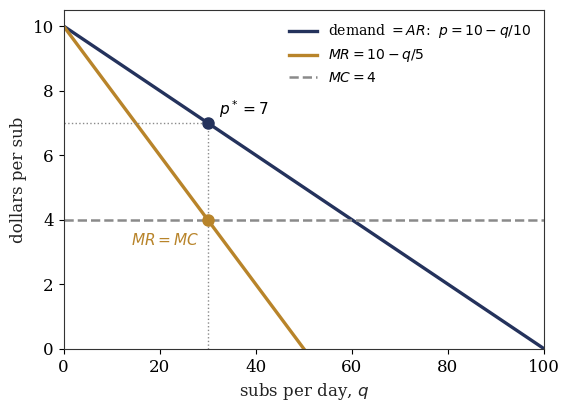

In [14]:
# Sub shop: demand (= average revenue), marginal revenue and marginal cost.
q = np.linspace(0, 100, 300)
qm = np.linspace(0, 50, 100)
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.plot(q, 10 - q / 10, color=NAVY, lw=2.4, label="demand $= AR$:  $p = 10 - q/10$")
ax.plot(qm, 10 - qm / 5, color=AMBER, lw=2.4, label="$MR = 10 - q/5$")
ax.axhline(4, color=GREY, lw=1.8, ls="--", label="$MC = 4$")
ax.plot([30, 30], [0, 7], color=GREY, lw=1, ls=":")
ax.plot([0, 30], [7, 7], color=GREY, lw=1, ls=":")
ax.plot(30, 4, "o", color=AMBER, ms=8, zorder=5)
ax.plot(30, 7, "o", color=NAVY, ms=8, zorder=5)
ax.annotate("$p^* = 7$", (30, 7), textcoords="offset points", xytext=(8, 6),
            fontsize=11)
ax.annotate("$MR = MC$", (30, 4), textcoords="offset points", xytext=(-6, -18),
            fontsize=11, ha="right", color=AMBER)
ax.set_xlim(0, 100); ax.set_ylim(0, 10.5)
ax.set_xlabel("subs per day, $q$"); ax.set_ylabel("dollars per sub")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "ar-mr-linear.png")
plt.show()

saved ..\slides\03_production-optimization\figs\short-run-supply.png


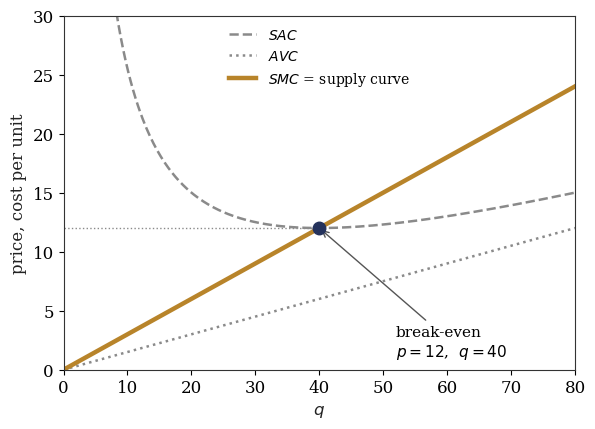

In [15]:
# The price-taking firm in the short run (K1 = 80): supply is SMC.
# Average variable cost is lowest at q = 0, so there is no shut-down kink.
w, v, K1 = 12.0, 3.0, 80.0
q = np.linspace(4, 80, 400)
q0 = np.linspace(0, 80, 100)
SAC = v * K1 / q + w * q / K1
fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.plot(q, SAC, color=GREY, lw=1.8, ls="--", label="$SAC$")
ax.plot(q0, w * q0 / K1, color=GREY, lw=1.8, ls=":", label="$AVC$")
ax.plot(q0, 2 * w * q0 / K1, color=AMBER, lw=3.2, label="$SMC$ = supply curve")
ax.plot([0, 40], [12, 12], color=GREY, lw=1, ls=":")
ax.plot(40, 12, "o", color=NAVY, ms=9, zorder=6)
ax.annotate("break-even\n$p = 12$,  $q = 40$", (40, 12), xytext=(52, 1.2),
            fontsize=11, arrowprops=dict(arrowstyle="->", color="#555555", lw=1))
ax.set_xlim(0, 80); ax.set_ylim(0, 30)
ax.set_xlabel("$q$"); ax.set_ylabel("price, cost per unit")
ax.legend(frameon=False, fontsize=10, loc="upper center")
savefig(fig, "short-run-supply.png")
plt.show()

saved ..\slides\03_production-optimization\figs\producer-surplus.png


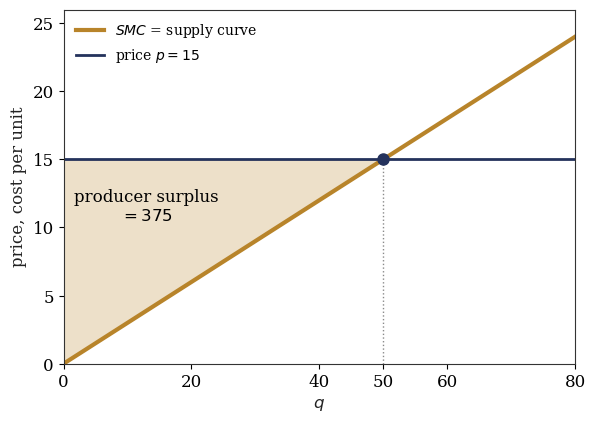

In [16]:
# Producer surplus for the price-taking firm (K1 = 80) at p = 15:
# the area between the price and SMC = 3q/10, from q = 0 to q = 50.
# Area = 375 = profit 135 + fixed cost 240. NS Figure 11.4.
w, K1, p = 12.0, 80.0, 15.0
qs = p * K1 / (2 * w)                          # = 50
q0 = np.linspace(0, 80, 100)
qf = np.linspace(0, qs, 100)
fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.fill_between(qf, 2 * w * qf / K1, p, color=AMBER, alpha=0.25)
ax.plot(q0, 2 * w * q0 / K1, color=AMBER, lw=3.0, label="$SMC$ = supply curve")
ax.plot([0, 80], [p, p], color=NAVY, lw=2.0, label="price $p = 15$")
ax.plot([qs, qs], [0, p], color=GREY, lw=1, ls=":")
ax.plot(qs, p, "o", color=NAVY, ms=8, zorder=6)
ax.text(13, 10.5, "producer surplus\n$= 375$", fontsize=12, ha="center")
ax.set_xlim(0, 80); ax.set_ylim(0, 26)
ax.set_xticks([0, 20, 40, 50, 60, 80])
ax.set_xlabel("$q$"); ax.set_ylabel("price, cost per unit")
ax.legend(frameon=False, fontsize=10, loc="upper left")
savefig(fig, "producer-surplus.png")
plt.show()

## Application: two farms and a missing labor market

Two farms with the same technology $q = \sqrt{TL}$ and unequal land (20 and
180 hectares). Each family has 50 days of labor, 100 in all. The horizontal
axis is labor on the small farm; the large farm gets the rest. With no labor
market each family works its own land (the point at 50). A labor market moves
labor until the marginal products are equal (the point at 10). The shaded
area is the output gained.

saved ..\slides\03_production-optimization\figs\farm-labor-allocation.png


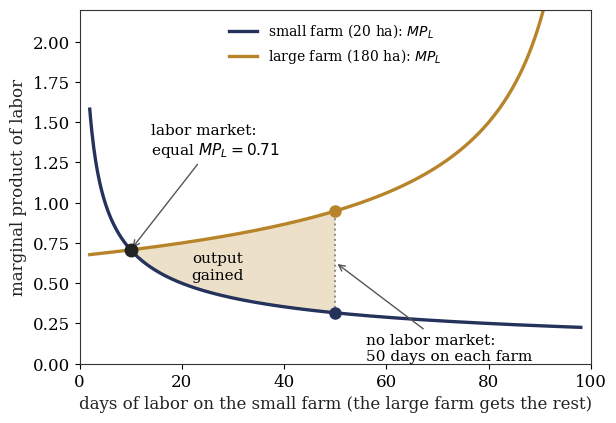

output without market 126.5, with market 141.4, gain 11.8%


In [17]:
TA, TB, LTOT = 20.0, 180.0, 100.0
LA = np.linspace(2, 98, 500)
MPA = 0.5 * np.sqrt(TA / LA)
MPB = 0.5 * np.sqrt(TB / (LTOT - LA))
Lstar = LTOT * TA / (TA + TB)                 # equal marginal products: 10
wstar = 0.5 * np.sqrt(TA / Lstar)             # 0.707

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.plot(LA, MPA, color=NAVY, lw=2.4, label="small farm (20 ha): $MP_L$")
ax.plot(LA, MPB, color=AMBER, lw=2.4, label="large farm (180 ha): $MP_L$")
gap = (LA >= Lstar) & (LA <= 50)
ax.fill_between(LA[gap], MPA[gap], MPB[gap], color=AMBER, alpha=0.25, lw=0)
ax.plot([50, 50], [0.5 * np.sqrt(TA / 50), 0.5 * np.sqrt(TB / 50)], color=GREY, lw=1.4, ls=":")
ax.plot(50, 0.5 * np.sqrt(TA / 50), "o", color=NAVY, ms=8, zorder=5)
ax.plot(50, 0.5 * np.sqrt(TB / 50), "o", color=AMBER, ms=8, zorder=5)
ax.plot(Lstar, wstar, "o", color="#222222", ms=9, zorder=6)
ax.annotate("labor market:\nequal $MP_L = 0.71$", (Lstar, wstar), xytext=(14, 1.30),
            fontsize=11, arrowprops=dict(arrowstyle="->", color="#555555", lw=1))
ax.annotate("no labor market:\n50 days on each farm", (50, 0.63), xytext=(56, 0.02),
            fontsize=11, arrowprops=dict(arrowstyle="->", color="#555555", lw=1))
ax.text(27, 0.60, "output\ngained", fontsize=11, ha="center", va="center")
ax.set_xlim(0, 100); ax.set_ylim(0, 2.2)
ax.set_xlabel("days of labor on the small farm (the large farm gets the rest)")
ax.set_ylabel("marginal product of labor")
ax.legend(frameon=False, fontsize=10, loc="upper center")
savefig(fig, "farm-labor-allocation.png")
plt.show()
q0 = np.sqrt(TA * 50) + np.sqrt(TB * 50)
q1 = np.sqrt(TA * Lstar) + np.sqrt(TB * (LTOT - Lstar))
print(f"output without market {q0:.1f}, with market {q1:.1f}, gain {100*(q1/q0-1):.1f}%")


## Conditional versus unconditional labor demand

Decreasing returns, $q = K^{1/4}L^{1/4}$, with $v = 3$ and output price $p = 48$.
Conditional (contingent) demand holds output at $q = 2$: $L^c = q^2\sqrt{v/w}$.
Unconditional (total) demand lets output adjust:
$L = \left[p\,(\beta/w)^{1-\alpha}(\alpha/v)^{\alpha}\right]^{1/(1-\alpha-\beta)}$.
Both give 2 workers at $w = 12$. At $w = 48$, conditional demand is 1 and
unconditional demand is 0.25.

saved ..\slides\03_production-optimization\figs\labor-demand-conditional-unconditional.png


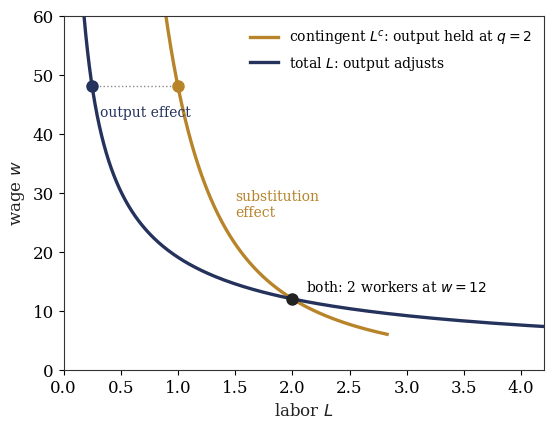

w=12: 2.0037700316210545 2.0113314279667946


In [18]:
a = b = 0.25
p, v, q0 = 48.0, 3.0, 2.0
w = np.linspace(6, 60, 400)
Lc = q0 ** (1 / (a + b)) * (b * v / (a * w)) ** (a / (a + b))
Lu = (p * (b / w) ** (1 - a) * (a / v) ** a) ** (1 / (1 - a - b))

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot(Lc, w, color=AMBER, lw=2.4, label="contingent $L^c$: output held at $q = 2$")
ax.plot(Lu, w, color=NAVY, lw=2.4, label="total $L$: output adjusts")
for (L0, w0, col) in [(2, 12, "#222222"), (1, 48, AMBER), (0.25, 48, NAVY)]:
    ax.plot(L0, w0, "o", color=col, ms=8, zorder=5)
ax.plot([0.25, 1], [48, 48], color=GREY, lw=1, ls=":")
ax.annotate("both: 2 workers at $w = 12$", (2, 12), textcoords="offset points", xytext=(10, 6), fontsize=10)
ax.annotate("substitution\neffect", (1.5, 26), fontsize=10, color=AMBER)
ax.annotate("output effect", (0.32, 43), fontsize=10, color=NAVY)
ax.set_xlim(0, 4.2); ax.set_ylim(0, 60)
ax.set_xlabel("labor $L$"); ax.set_ylabel("wage $w$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "labor-demand-conditional-unconditional.png")
plt.show()
print("w=12:", Lc[np.argmin(abs(w-12))], Lu[np.argmin(abs(w-12))])